In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [46]:
# Make output folders if they do not already exist
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Set seed so results are reproducible
np.random.seed(123)

In [47]:
def payoffs(i, N, b, c):
    
    pi_C = ((i - 1) * (b - c) + (N - i) * (-c)) / (N - 1)
    pi_A = i / (N - 1)

    return pi_C, pi_A

In [48]:
def moran_trial(N, b, c=0.2, s=0.1, max_steps=300000):
    
    i = 1 

    for step in range(max_steps):
        
        if i == 0:
            return 0
        if i == N:
            return 1
        
        pi_C, pi_A = payoffs(i, N, b, c)
        
        f_C = 1 + s * pi_C
        f_A = 1 + s * pi_A
        
        F_C = i * f_C
        F_A = (N - i) * f_A
        F_total = F_C + F_A
        
        prob_C_reproduces = F_C / F_total
        prob_C_dies = i / N
        
        C_reproduces = np.random.rand() < prob_C_reproduces
        C_dies = np.random.rand() < prob_C_dies
        
        if C_reproduces and not C_dies:
            i += 1
        elif (not C_reproduces) and C_dies:
            i -= 1
    
    return 1 if i == N else 0

In [49]:
def estimate_fixation_probability(N, b, c=0.2, s=0.1, num_trials=5000):
    
    fixation_count = 0
    
    for trial in range(num_trials):
        fixation_count += moran_trial(N=N, b=b, c=c, s=s)
    
    return fixation_count / num_trials

In [50]:
# Population sizes and cooperation benefits for line plots
N_values = [10, 25, 50, 100, 250, 500]
b_values = [0.5, 1.2, 1.5, 2.0, 3.0]

c = 0.2
s = 0.1
num_trials = 5000

In [51]:
results = []

for b in b_values:
    for N in N_values:
        rho = estimate_fixation_probability(
            N=N,
            b=b,
            c=c,
            s=s,
            num_trials=num_trials
        )
        
        neutral = 1 / N
        relative_advantage = rho - neutral
        
        results.append({
            "N": N,
            "b": b,
            "c": c,
            "s": s,
            "num_trials": num_trials,
            "fixation_probability": rho,
            "neutral_baseline": neutral,
            "relative_advantage": relative_advantage
        })
        
        print(
            f"N = {N}, b = {b}, rho = {rho:.4f}, "
            f"neutral = {neutral:.4f}, advantage = {relative_advantage:.4f}"
        )

df = pd.DataFrame(results)
df

N = 10, b = 0.5, rho = 0.0796, neutral = 0.1000, advantage = -0.0204
N = 25, b = 0.5, rho = 0.0236, neutral = 0.0400, advantage = -0.0164
N = 50, b = 0.5, rho = 0.0048, neutral = 0.0200, advantage = -0.0152
N = 100, b = 0.5, rho = 0.0012, neutral = 0.0100, advantage = -0.0088
N = 250, b = 0.5, rho = 0.0000, neutral = 0.0040, advantage = -0.0040
N = 500, b = 0.5, rho = 0.0000, neutral = 0.0020, advantage = -0.0020
N = 10, b = 1.2, rho = 0.0886, neutral = 0.1000, advantage = -0.0114
N = 25, b = 1.2, rho = 0.0322, neutral = 0.0400, advantage = -0.0078
N = 50, b = 1.2, rho = 0.0134, neutral = 0.0200, advantage = -0.0066
N = 100, b = 1.2, rho = 0.0054, neutral = 0.0100, advantage = -0.0046
N = 250, b = 1.2, rho = 0.0006, neutral = 0.0040, advantage = -0.0034
N = 500, b = 1.2, rho = 0.0000, neutral = 0.0020, advantage = -0.0020
N = 10, b = 1.5, rho = 0.0862, neutral = 0.1000, advantage = -0.0138
N = 25, b = 1.5, rho = 0.0342, neutral = 0.0400, advantage = -0.0058
N = 50, b = 1.5, rho = 0.017

,N,b,c,s,num_trials,fixation_probability,neutral_baseline,relative_advantage
0,10,0.5,0.2,0.1,5000,0.0796,0.100,-0.0204
1,25,0.5,0.2,0.1,5000,0.0236,0.040,-0.0164
2,50,0.5,0.2,0.1,5000,0.0048,0.020,-0.0152
3,100,0.5,0.2,0.1,5000,0.0012,0.010,-0.0088
4,250,0.5,0.2,0.1,5000,0.0000,0.004,-0.0040
5,500,0.5,0.2,0.1,5000,0.0000,0.002,-0.0020
6,10,1.2,0.2,0.1,5000,0.0886,0.100,-0.0114
7,25,1.2,0.2,0.1,5000,0.0322,0.040,-0.0078
8,50,1.2,0.2,0.1,5000,0.0134,0.020,-0.0066
9,100,1.2,0.2,0.1,5000,0.0054,0.010,-0.0046


In [52]:
df_pivot = df.pivot(
    index="N",
    columns="b",
    values="fixation_probability"
)

df_pivot

b,0.5,1.2,1.5,2.0,3.0
N,,,,,
10,0.0796,0.0886,0.0862,0.0938,0.1110
25,0.0236,0.0322,0.0342,0.0386,0.0560
50,0.0048,0.0134,0.0172,0.0246,0.0362
100,0.0012,0.0054,0.0084,0.0124,0.0248
250,0.0000,0.0006,0.0022,0.0040,0.0102
500,0.0000,0.0000,0.0000,0.0026,0.0044


In [53]:
df.to_csv("results/fixation_results.csv", index=False)
df_pivot.to_csv("results/fixation_results_pivot.csv")

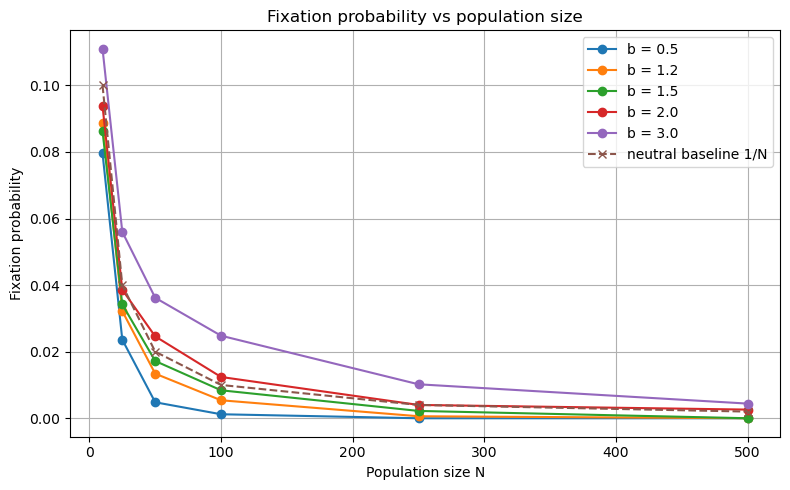

In [54]:
plt.figure(figsize=(8, 5))

for b in b_values:
    sub = df[df["b"] == b]
    plt.plot(
        sub["N"],
        sub["fixation_probability"],
        marker="o",
        label=f"b = {b}"
    )

plt.plot(
    N_values,
    [1 / N for N in N_values],
    linestyle="--",
    marker="x",
    label="neutral baseline 1/N"
)

plt.xlabel("Population size N")
plt.ylabel("Fixation probability")
plt.title("Fixation probability vs population size")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("figures/fixation_probability_vs_N.png", dpi=300, bbox_inches="tight")
plt.show()

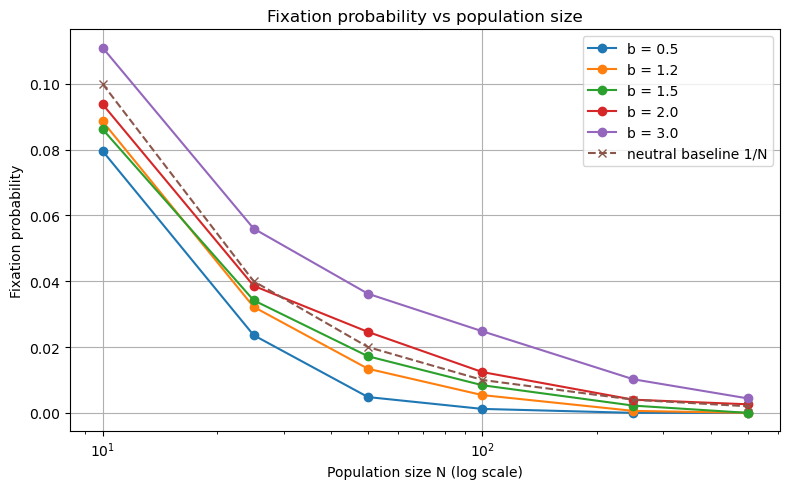

In [55]:
plt.figure(figsize=(8, 5))

for b in b_values:
    sub = df[df["b"] == b]
    plt.plot(
        sub["N"],
        sub["fixation_probability"],
        marker="o",
        label=f"b = {b}"
    )

plt.plot(
    N_values,
    [1 / N for N in N_values],
    linestyle="--",
    marker="x",
    label="neutral baseline 1/N"
)

plt.xscale("log")

plt.xlabel("Population size N (log scale)")
plt.ylabel("Fixation probability")
plt.title("Fixation probability vs population size")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("figures/fixation_probability_vs_N_logscale.png", dpi=300, bbox_inches="tight")
plt.show()

In [56]:
# Population sizes and cooperation benefits for heatmaps
N_grid = [10, 20, 30, 50, 75, 100, 150, 250, 500]
b_grid = np.arange(0.5, 3.1, 0.25)

c = 0.2
s = 0.1
num_trials_heatmap = 2000

In [57]:
heatmap_results = []

for N in N_grid:
    for b in b_grid:
        rho = estimate_fixation_probability(
            N=N,
            b=b,
            c=c,
            s=s,
            num_trials=num_trials_heatmap
        )
        
        neutral = 1 / N
        relative_advantage = rho - neutral
        
        heatmap_results.append({
            "N": N,
            "b": b,
            "c": c,
            "s": s,
            "num_trials": num_trials_heatmap,
            "fixation_probability": rho,
            "neutral_baseline": neutral,
            "relative_advantage": relative_advantage
        })
        
        print(
            f"N = {N}, b = {b:.2f}, rho = {rho:.4f}, "
            f"neutral = {neutral:.4f}, advantage = {relative_advantage:.4f}"
        )

heatmap_df = pd.DataFrame(heatmap_results)
heatmap_df.head()

N = 10, b = 0.50, rho = 0.0800, neutral = 0.1000, advantage = -0.0200
N = 10, b = 0.75, rho = 0.0845, neutral = 0.1000, advantage = -0.0155
N = 10, b = 1.00, rho = 0.0810, neutral = 0.1000, advantage = -0.0190
N = 10, b = 1.25, rho = 0.0785, neutral = 0.1000, advantage = -0.0215
N = 10, b = 1.50, rho = 0.0900, neutral = 0.1000, advantage = -0.0100
N = 10, b = 1.75, rho = 0.1130, neutral = 0.1000, advantage = 0.0130
N = 10, b = 2.00, rho = 0.0890, neutral = 0.1000, advantage = -0.0110
N = 10, b = 2.25, rho = 0.0960, neutral = 0.1000, advantage = -0.0040
N = 10, b = 2.50, rho = 0.1015, neutral = 0.1000, advantage = 0.0015
N = 10, b = 2.75, rho = 0.1040, neutral = 0.1000, advantage = 0.0040
N = 10, b = 3.00, rho = 0.1020, neutral = 0.1000, advantage = 0.0020
N = 20, b = 0.50, rho = 0.0390, neutral = 0.0500, advantage = -0.0110
N = 20, b = 0.75, rho = 0.0305, neutral = 0.0500, advantage = -0.0195
N = 20, b = 1.00, rho = 0.0370, neutral = 0.0500, advantage = -0.0130
N = 20, b = 1.25, rho = 

,N,b,c,s,num_trials,fixation_probability,neutral_baseline,relative_advantage
0,10,0.50,0.2,0.1,2000,0.0800,0.1,-0.0200
1,10,0.75,0.2,0.1,2000,0.0845,0.1,-0.0155
2,10,1.00,0.2,0.1,2000,0.0810,0.1,-0.0190
3,10,1.25,0.2,0.1,2000,0.0785,0.1,-0.0215
4,10,1.50,0.2,0.1,2000,0.0900,0.1,-0.0100


In [58]:
heatmap_df.to_csv("results/heatmap_fixation_results.csv", index=False)

In [59]:
fixation_matrix = heatmap_df.pivot(
    index="N",
    columns="b",
    values="fixation_probability"
)

advantage_matrix = heatmap_df.pivot(
    index="N",
    columns="b",
    values="relative_advantage"
)

fixation_matrix

b,0.50,0.75,1.00,1.25,1.50,1.75,2.00,2.25,2.50,2.75,3.00
N,,,,,,,,,,,
10,0.0800,0.0845,0.0810,0.0785,0.0900,0.1130,0.0890,0.0960,0.1015,0.1040,0.1020
20,0.0390,0.0305,0.0370,0.0455,0.0495,0.0485,0.0555,0.0490,0.0555,0.0600,0.0670
30,0.0155,0.0175,0.0290,0.0225,0.0290,0.0295,0.0385,0.0385,0.0385,0.0375,0.0465
50,0.0085,0.0115,0.0135,0.0120,0.0155,0.0155,0.0185,0.0275,0.0265,0.0315,0.0350
75,0.0025,0.0055,0.0055,0.0100,0.0100,0.0110,0.0150,0.0255,0.0155,0.0260,0.0285
100,0.0005,0.0020,0.0020,0.0045,0.0080,0.0120,0.0150,0.0155,0.0180,0.0190,0.0240
150,0.0000,0.0000,0.0000,0.0025,0.0040,0.0045,0.0090,0.0090,0.0135,0.0175,0.0240
250,0.0000,0.0000,0.0000,0.0000,0.0010,0.0075,0.0030,0.0055,0.0070,0.0075,0.0135
500,0.0000,0.0000,0.0000,0.0000,0.0005,0.0005,0.0020,0.0040,0.0050,0.0040,0.0055


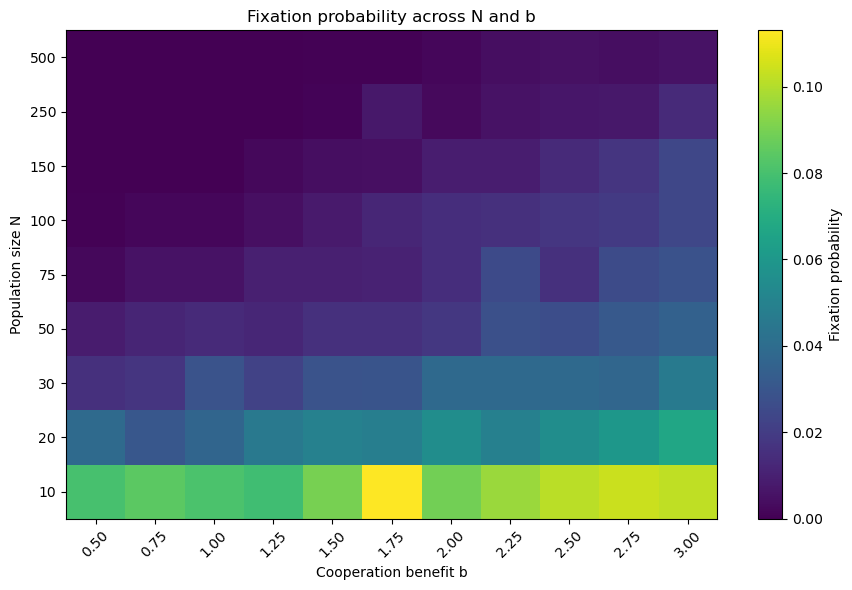

In [60]:
plt.figure(figsize=(9, 6))

plt.imshow(
    fixation_matrix.values,
    aspect="auto",
    origin="lower",
    cmap="viridis"
)

plt.colorbar(label="Fixation probability")

plt.xticks(
    ticks=np.arange(len(fixation_matrix.columns)),
    labels=[f"{b:.2f}" for b in fixation_matrix.columns],
    rotation=45
)

plt.yticks(
    ticks=np.arange(len(fixation_matrix.index)),
    labels=fixation_matrix.index
)

plt.xlabel("Cooperation benefit b")
plt.ylabel("Population size N")
plt.title("Fixation probability across N and b")
plt.tight_layout()

plt.savefig("figures/heatmap_fixation_probability.png", dpi=300, bbox_inches="tight")
plt.show()

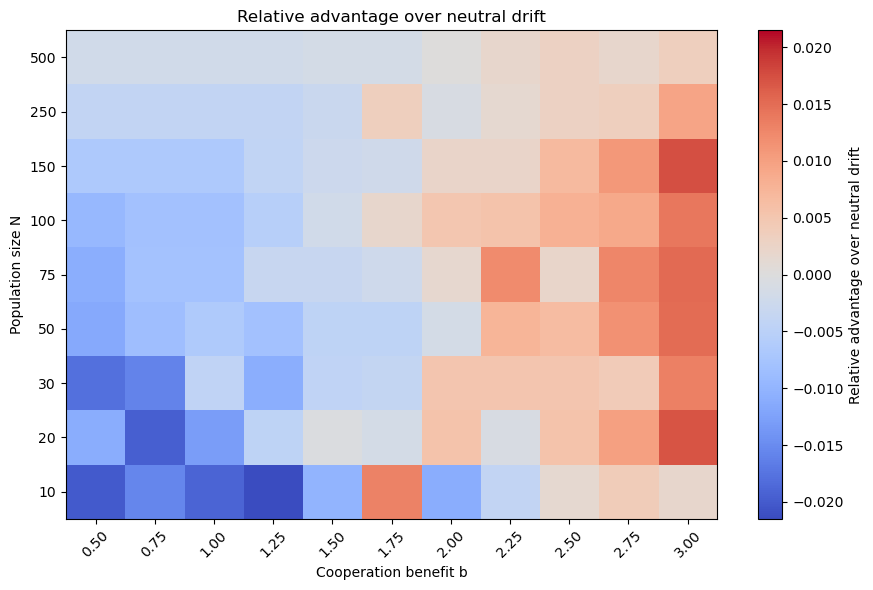

In [61]:
max_abs = np.max(np.abs(advantage_matrix.values))

plt.figure(figsize=(9, 6))

plt.imshow(
    advantage_matrix.values,
    aspect="auto",
    origin="lower",
    cmap="coolwarm",
    vmin=-max_abs,
    vmax=max_abs
)

plt.colorbar(label="Relative advantage over neutral drift")

plt.xticks(
    ticks=np.arange(len(advantage_matrix.columns)),
    labels=[f"{b:.2f}" for b in advantage_matrix.columns],
    rotation=45
)

plt.yticks(
    ticks=np.arange(len(advantage_matrix.index)),
    labels=advantage_matrix.index
)

plt.xlabel("Cooperation benefit b")
plt.ylabel("Population size N")
plt.title("Relative advantage over neutral drift")
plt.tight_layout()

plt.savefig("figures/heatmap_relative_advantage.png", dpi=300, bbox_inches="tight")
plt.show()

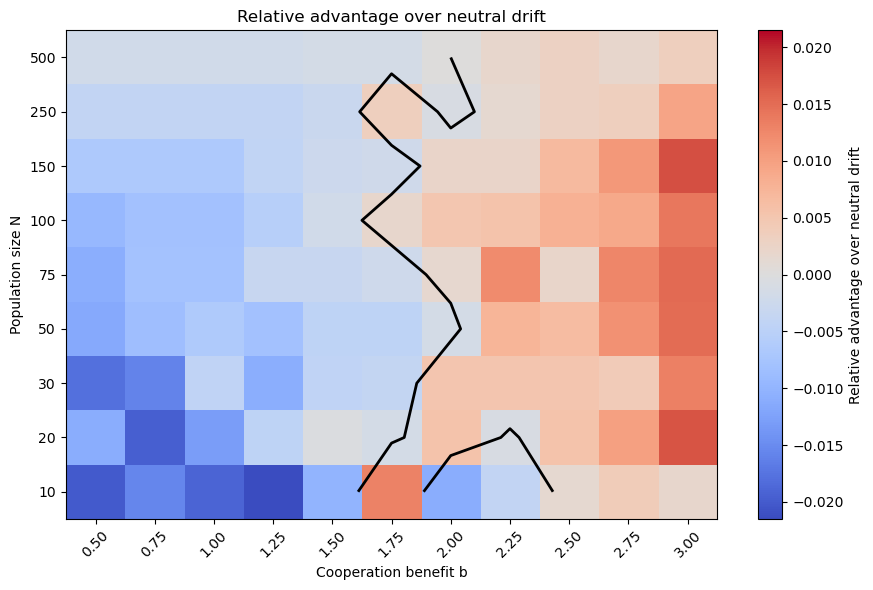

In [62]:
max_abs = np.max(np.abs(advantage_matrix.values))

plt.figure(figsize=(9, 6))

plt.imshow(
    advantage_matrix.values,
    aspect="auto",
    origin="lower",
    cmap="coolwarm",
    vmin=-max_abs,
    vmax=max_abs
)

plt.colorbar(label="Relative advantage over neutral drift")

# Add contour line where relative advantage = 0
X, Y = np.meshgrid(
    np.arange(len(advantage_matrix.columns)),
    np.arange(len(advantage_matrix.index))
)

plt.contour(
    X,
    Y,
    advantage_matrix.values,
    levels=[0],
    colors="black",
    linewidths=2
)

plt.xticks(
    ticks=np.arange(len(advantage_matrix.columns)),
    labels=[f"{b:.2f}" for b in advantage_matrix.columns],
    rotation=45
)

plt.yticks(
    ticks=np.arange(len(advantage_matrix.index)),
    labels=advantage_matrix.index
)

plt.xlabel("Cooperation benefit b")
plt.ylabel("Population size N")
plt.title("Relative advantage over neutral drift")
plt.tight_layout()

plt.savefig("figures/heatmap_relative_advantage_contour.png", dpi=300, bbox_inches="tight")
plt.show()